NAMA : FIRDA NURKHAIRANI

NIM : 24031554209

KELAS : 24 A

# 1.2 Mempelajari Penggunaan Driver Neo4J

In [2]:
!pip install neo4j


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Firan1da")

In [5]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a : Person {name : $name})"
        "MERGE (friend : Person {name : $friend_name})"
        "MERGE (a) - [:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j"
    )

In [6]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a : Person) - [:KNOWS]->(friend)" 
        "WHERE a.name = $name"
        "RETURN friend.name ORDER BY friend.name",
        name=name, 
        database_="neo4j", 
        routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

In [7]:

def print_friends(driver, name):
    query = """
    MATCH (a:Person)-[:KNOWS]->(friend)
    WHERE a.name = $name
    RETURN friend.name
    ORDER BY friend.name
    """

    records, _, _ = driver.execute_query(
        query,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend.name"])


In [8]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


# Pertanyaan

1. Apa nama database yang digunakan pada tutorial ini?
2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!
3. Apa jenis graf pertemanan yang telah dibuat di sini?

# Jawaban
1. Nama databasenya adalah database_ = neo4j sebagai parameter pemanggilan fungsi driver.
2. Nama lainnya yaitu USE<nama_database> untuk mengalihkan konteks kueri ke database lain berada dalam satu instance server yang sama.
3. (a)-[:KNOWS]->(friend) yang jenis tersebut grafnya berarah (directed graph).

# Coba

In [64]:
import pandas as pd
import zipfile
import os

In [65]:
!curl -L -o ecommerce-dataset.zip "https://www.kaggle.com/api/v1/dataset/download/retailrocket/ecommerce-datasett"

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
100   5557   0   5557   0      0   8602      0                              0
100   5557   0   5557   0      0   8599      0                              0
100   5557   0   5557   0      0   8596      0                              0


In [66]:

file_zip = "ecommerce-dataset.zip"

print("File ditemukan:", os.path.exists(file_zip))

if os.path.exists(file_zip):
    print("Ukuran file:", os.path.getsize(file_zip), "bytes")

File ditemukan: True
Ukuran file: 5557 bytes


# 1.3 Proses Impor Data dari RetailRocket

In [9]:
from neo4j import GraphDatabase

uri_database = "neo4j://127.0.0.1:7687"
user_database = "neo4j"
pass_database = "Firan1da"

driver = GraphDatabase.driver(uri_database, auth=(user_database, pass_database))

session = driver.session(database="neo4j")

In [10]:
print("Mekanisme pembuatan driver dan session Neo4j berhasil disiapkan!")

Mekanisme pembuatan driver dan session Neo4j berhasil disiapkan!


In [44]:
# Sesuaikan dengan konfigurasi Neo4j milikmu
URI = "neo4j://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = "Firan1da"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

# Memeriksa koneksi
driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


In [39]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    FOREACH (_ IN CASE WHEN row.event = 'view'
                       THEN [1] ELSE [] END |
        MERGE (v)-[:VIEWED]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'addtocart'
                       THEN [1] ELSE [] END |
        MERGE (v)-[:ADDED_TO_CART]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'transaction'
                       THEN [1] ELSE [] END |
        MERGE (v)-[:BOUGHT {
            transactionid: row.transactionid
        }]->(i)
    )
    """
    tx.run(cypher_query, batch=batch).consume()


In [13]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorid IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemid IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT event_id IF NOT EXISTS
        FOR (e:Event)
        REQUIRE e.event_id IS UNIQUE
    """)

In [169]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    WHERE row.event = 'view'

    MERGE (v)-[:VIEWED]->(i)
    """

    tx.run(cypher_query, batch=batch)

In [40]:

from neo4j import GraphDatabase
import pandas as pd
from tqdm import tqdm

# Buat ulang koneksi jika driver sudah ditutup
URI = "neo4j://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = "Firan1da"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)
driver.verify_connectivity()

batch_size = 5000
csv_file_path = "events_filtered.csv"

total_rows = sum(1 for _ in open(csv_file_path)) - 1
total_chunks = (total_rows + batch_size - 1) // batch_size

with driver.session(database="neo4j") as session:
    create_constraints(session)

    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    for chunk in tqdm(chunks, total=total_chunks,
                      desc="Mengimpor Batch Data"):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor selesai.")

Mengimpor Batch Data: 100%|██████████| 102/102 [00:46<00:00,  2.20it/s]

Proses impor selesai.


# 2. Soal UTS

# 2.1 Wrangling dan EDA

In [19]:
import pandas as pd
import random
import math
import os
import networkx as nx
import matplotlib.pyplot as plt

In [20]:
df = pd.read_csv("events.csv")

df["datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms"
)

print("Tanggal paling awal:", df["datetime"].min())
print("Tanggal paling akhir:", df["datetime"].max())
print("Jumlah seluruh data:", len(df))

Tanggal paling awal: 2015-05-03 03:00:04.384000
Tanggal paling akhir: 2015-09-18 02:59:47.788000
Jumlah seluruh data: 2756101


In [25]:
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

p1_mulai, p1_selesai = "2015-08-19", "2015-08-31"
p2_mulai, p2_selesai = "2015-09-01", "2015-09-17"

df_p1 = df[
    (df['datetime'] >= p1_mulai) &
    (df['datetime'] < "2015-09-01")
]

df_p2 = df[
    (df['datetime'] >= p2_mulai) &
    (df['datetime'] < "2015-09-18")
]

df_filtered = pd.concat([df_p1, df_p2], ignore_index=True)
df_filtered = df_filtered.drop(columns=['datetime'])
df_filtered.to_csv("events_filtered.csv", index=False)

print("Jumlah data P1:", len(df_p1))
print("Jumlah data P2:", len(df_p2))
print("Total data:", len(df_filtered))

Jumlah data P1: 231752
Jumlah data P2: 302182
Total data: 533934


In [29]:
# 1. Membaca file utama events.csv hasil unduhan CMD tadi
df = pd.read_csv("events.csv")

# Menampilkan 5 data teratas untuk mengecek fitur (kolom) data sesuai Poin 2
print("--- 5 Baris Data Teratas ---")
print(df.head())

# 2. Mengubah timestamp (milidetik) menjadi tanggal resmi agar mudah disaring
df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

# 3. Menyaring rentang tanggal kustom UTS Anda
# Silakan ganti rentang tanggal di bawah agar beda dengan mahasiswa lain
p1_mulai, p1_selesai = "2015-08-19", "2015-08-31"
p2_mulai, p2_selesai = "2015-09-01", "2015-09-17"
df_p1 = df[(df['datetime'] >= p1_mulai) & (df['datetime'] <= p1_selesai)]
df_p2 = df[(df['datetime'] >= p2_mulai) & (df['datetime'] <= p2_selesai)]

df_filtered = pd.concat(
    [df_p1, df_p2],
    ignore_index=True
)

# Menghapus kolom pembantu agar format kembali asli
df_filtered = df_filtered.drop(columns=['datetime'])

# 4. Menyimpan potongan data kustom Anda menjadi file baru
df_filtered.to_csv("events_filtered.csv", index=False)

print("\nProses pemotongan data selesai!")
print("Jumlah data rentang pertama:", len(df_p1))
print("Jumlah data rentang kedua:", len(df_p2))
print("Total data hasil filter:", len(df_filtered))
print("File tersimpan sebagai events_filtered.csv")

--- 5 Baris Data Teratas ---
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN

Proses pemotongan data selesai!
Jumlah data rentang pertama: 213125
Jumlah data rentang kedua: 292054
Total data hasil filter: 505179
File tersimpan sebagai events_filtered.csv


In [23]:
df = pd.read_csv("events.csv")

# Mengubah timestamp menjadi datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

# P1: Training (19–31 Agustus 2015)
tanggal_mulai1 = "2015-08-19"
tanggal_selesai1 = "2015-08-31"

df_train = df[
    (df["datetime"] >= tanggal_mulai1) &
    (df["datetime"] < "2015-09-01")
].copy()

# P2: Testing (1–17 September 2015)
tanggal_mulai2 = "2015-09-01"
tanggal_selesai2 = "2015-09-17"

df_test = df[
    (df["datetime"] >= tanggal_mulai2) &
    (df["datetime"] < "2015-09-18")
].copy()

# Menghapus kolom datetime jika tidak diperlukan
df_train.drop(columns=["datetime"], inplace=True)
df_test.drop(columns=["datetime"], inplace=True)

# Menyimpan hasil filter
df_train.to_csv("events_train.csv", index=False)
df_test.to_csv("events_test.csv", index=False)

# Menampilkan jumlah data
print("Jumlah data training:", len(df_train))
print("Jumlah data testing:", len(df_test))
print("Total data training dan testing:", len(df_train) + len(df_test))

Jumlah data training: 231752
Jumlah data testing: 302182
Total data training dan testing: 533934


In [26]:
# 1. Membaca data mentah
file_sumber = "events.csv"
file_output = "events_filtered.csv"

print("Memulai proses membaca data mentah...")
df = pd.read_csv(file_sumber)

# 2. Konversi timestamp ke datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

# 3. Filter P1: Training (19–31 Agustus 2015)
tgl_p1_mulai = "2015-08-19"
tgl_p1_selesai = "2015-09-01"

df_p1 = df[
    (df["datetime"] >= tgl_p1_mulai) &
    (df["datetime"] < tgl_p1_selesai)
]

# 4. Filter P2: Testing (1–17 September 2015)
tgl_p2_mulai = "2015-09-01"
tgl_p2_selesai = "2015-09-18"

df_p2 = df[
    (df["datetime"] >= tgl_p2_mulai) &
    (df["datetime"] < tgl_p2_selesai)
]

# 5. Gabungkan data
df_gabungan = pd.concat([df_p1, df_p2], ignore_index=True)

# 6. Bersihkan transactionid
df_gabungan["transactionid"] = (
    df_gabungan["transactionid"].fillna("").astype(str)
)

# 7. Hapus kolom datetime
df_final = df_gabungan.drop(columns=["datetime"])

# 8. Simpan hasil
df_final.to_csv(file_output, index=False)

# 9. Laporan hasil
print(f"Jumlah data P1 (Training): {len(df_p1)} baris")
print(f"Jumlah data P2 (Testing): {len(df_p2)} baris")
print(f"Total data tersimpan: {len(df_final)} baris")
print(f"File output: {file_output}")

Memulai proses membaca data mentah...
Jumlah data P1 (Training): 231752 baris
Jumlah data P2 (Testing): 302182 baris
Total data tersimpan: 533934 baris
File output: events_filtered.csv


In [30]:
# Fungsi untuk mengambil statistik grafik dari Neo4j
def dapatkan_komposisi(tx):
    # 1. Hitung jumlah simpul berdasarkan labelnya
    kueri_node = "MATCH (n) RETURN labels(n)[0] AS Label, count(n) AS Jumlah"
    hasil_node = tx.run(kueri_node)
    print("--- Jumlah Simpul (Nodes) di Neo4j ---")
    for rec in hasil_node:
        print(f"Label: {rec['Label']} | Total: {rec['Jumlah']}")
        
    # 2. Hitung jumlah hubungan berdasarkan tipenya
    kueri_rel = "MATCH ()-[r]->() RETURN type(r) AS JenisHubungan, count(r) AS Jumlah"
    hasil_rel = tx.run(kueri_rel)
    print("\n--- Jumlah Hubungan (Relationships) di Neo4j ---")
    for rec in hasil_rel:
        print(f"Relasi: {rec['JenisHubungan']} | Total: {rec['Jumlah']}")

# Jalankan kueri
with driver.session(database="neo4j") as session:
    session.execute_read(dapatkan_komposisi)


--- Jumlah Simpul (Nodes) di Neo4j ---
Label: Person | Total: 4
Label: Visitor | Total: 299363
Label: Item | Total: 112356

--- Jumlah Hubungan (Relationships) di Neo4j ---
Relasi: KNOWS | Total: 3
Relasi: VIEWED | Total: 421376
Relasi: SIMILAR_TO | Total: 5


C:\Users\ZANI\AppData\Local\Temp\ipykernel_32544\2814119958.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


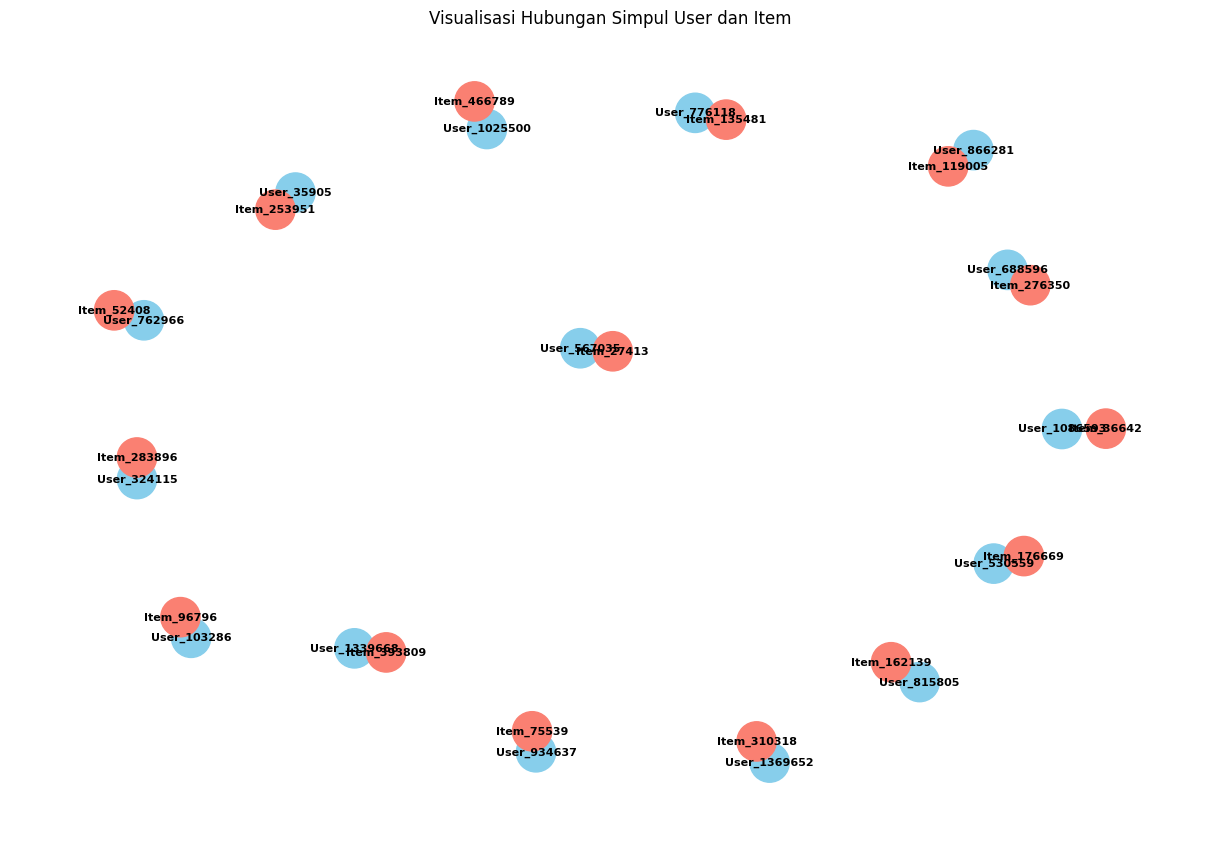

--- Karakteristik Graf Bipartite Terbentuk ---
Total Simpul Terdeteksi (Dimensi Graf): 30
Total Garis Hubungan Terbentuk: 15


In [41]:
# 1. Buka kembali file data kustom Anda
df_kustom = pd.read_csv("events_filtered.csv")

# 2. Karakteristik User & Item (Mengambil sampel kecil 15 baris data agar gambar rapi & tidak penuh)
df_sample = df_kustom.head(15)

# Membuat objek graf kosong dari networkx
G = nx.Graph()

# 3. Proses VSM: Memetakan relasi interaksi User (Visitor) ke Item
for _, row in df_sample.iterrows():
    user_node = f"User_{int(row['visitorid'])}"
    item_node = f"Item_{int(row['itemid'])}"
    
    # Tambahkan simpul dan hubungannya ke dalam graf networkx
    G.add_node(user_node, type='User')
    G.add_node(item_node, type='Item')
    G.add_edge(user_node, item_node, weight=row['event'])

# 4. Pewarnaan Grafik (User diberi warna biru, Item diberi warna oranye/merah)
warna_simpul = []
for node, attrs in G.nodes(data=True):
    if attrs.get('type') == 'User':
        warna_simpul.append('skyblue')
    else:
        warna_simpul.append('salmon')

# 5. Menggambar struktur graf secara visual
plt.figure(figsize=(12, 8))
posisi = nx.spring_layout(G, seed=42, weight=None) # Pengaturan posisi simpul agar menyebar rapi

nx.draw(
    G, posisi, with_labels=True, 
    node_color=warna_simpul, node_size=800, 
    edge_color='gray', font_size=8, font_weight='bold'
)

plt.title("Visualisasi Hubungan Simpul User dan Item", fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()

# Menampilkan karakteristik dimensi data untuk laporan Anda
print("--- Karakteristik Graf Bipartite Terbentuk ---")
print("Total Simpul Terdeteksi (Dimensi Graf):", G.number_of_nodes())
print("Total Garis Hubungan Terbentuk:", G.number_of_edges())

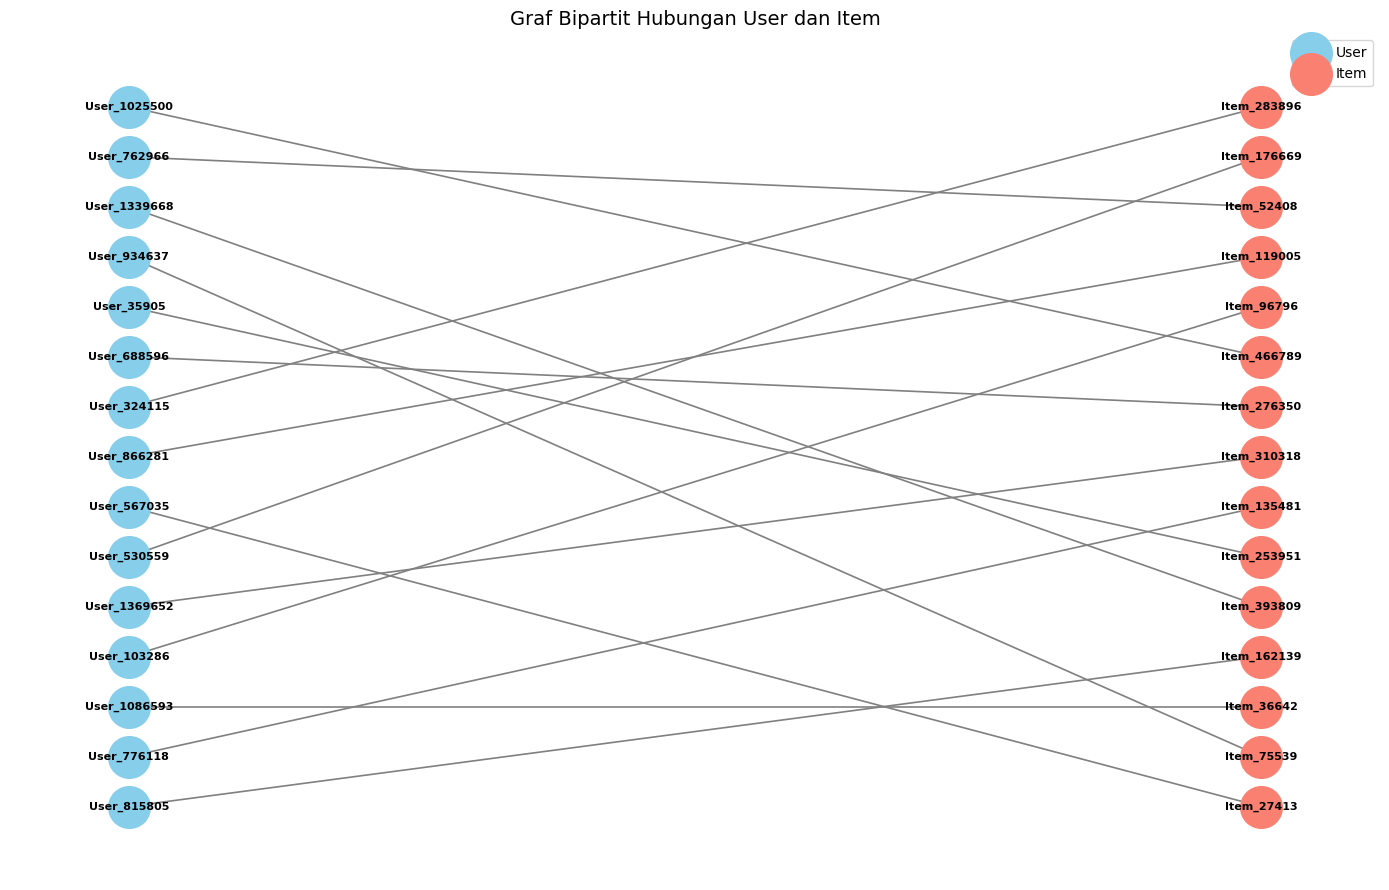

--- Karakteristik Graf Bipartit ---
Jumlah simpul User: 15
Jumlah simpul Item: 15
Total simpul: 30
Total hubungan: 15


In [42]:
# 1. Membaca data
df_kustom = pd.read_csv("events_filtered.csv")

# Mengambil sampel 15 baris
df_sample = df_kustom.head(15)

# 2. Membuat graf
G = nx.Graph()

for _, row in df_sample.iterrows():
    user_node = f"User_{int(row['visitorid'])}"
    item_node = f"Item_{int(row['itemid'])}"

    G.add_node(user_node, type="User", bipartite=0)
    G.add_node(item_node, type="Item", bipartite=1)

    # Event disimpan sebagai atribut, bukan bobot numerik
    G.add_edge(user_node, item_node, event=row["event"])

# 3. Memisahkan simpul User dan Item
user_nodes = [
    node for node, attrs in G.nodes(data=True)
    if attrs["type"] == "User"
]

item_nodes = [
    node for node, attrs in G.nodes(data=True)
    if attrs["type"] == "Item"
]

# 4. Menentukan posisi User kiri dan Item kanan
posisi = nx.bipartite_layout(
    G,
    nodes=user_nodes,
    align="vertical"
)

# 5. Menentukan warna simpul
warna_simpul = [
    "skyblue" if G.nodes[node]["type"] == "User"
    else "salmon"
    for node in G.nodes()
]

# 6. Menggambar graf
plt.figure(figsize=(14, 9))

nx.draw_networkx_nodes(
    G, posisi,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=900,
    label="User"
)

nx.draw_networkx_nodes(
    G, posisi,
    nodelist=item_nodes,
    node_color="salmon",
    node_size=900,
    label="Item"
)

nx.draw_networkx_edges(
    G, posisi,
    edge_color="gray",
    width=1.2
)

nx.draw_networkx_labels(
    G, posisi,
    font_size=8,
    font_weight="bold"
)

plt.title("Graf Bipartit Hubungan User dan Item", fontsize=14)
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

# 7. Statistik graf
print("--- Karakteristik Graf Bipartit ---")
print("Jumlah simpul User:", len(user_nodes))
print("Jumlah simpul Item:", len(item_nodes))
print("Total simpul:", G.number_of_nodes())
print("Total hubungan:", G.number_of_edges())

Nomer 6

Berdasarkan hasil eksplorasi graf, proyeksi berbasis User (User-Based Projection) dipilih karena menghubungkan pengguna yang memiliki kesamaan interaksi terhadap item. Proyeksi ini cocok untuk sistem rekomendasi menggunakan Collaborative Filtering dan KNN, yaitu dengan merekomendasikan item berdasarkan pengguna lain yang memiliki pola interaksi serupa. Selain itu, kemudahan menghitung kemiripan antar pengguna dapat membantu proses penentuan rekomendasi yang lebih terarah.

In [45]:
# 1. Mengambil 1 User acak dari data filtered Anda secara reproduksibel
df_cek = pd.read_csv("events_filtered.csv")
daftar_user = df_cek['visitorid'].unique()

# Gunakan seed 42 agar nilainya konstan saat dijalankan ulang
random.seed(42)
user_acuan = int(random.choice(daftar_user))
print(f"User acuan acak terpilih untuk UTS: {user_acuan}")

# 2. Definisikan fungsi untuk menghitung dan menyimpan ke Neo4j
def eksekusi_similarity_uts(tx, uid):
    # Gabungan kueri (a) dan (b) untuk mencari 5 tetangga terdekat & menyimpannya
    kueri = """
    MATCH (v1:Visitor {visitorId: $target_id})-[r1:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)<-[r2:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
    WITH v1, v2, count(DISTINCT i) AS irisan
    
    MATCH (v1)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i1:Item) 
    WITH v1, v2, irisan, count(DISTINCT i1) AS total_v1
    
    MATCH (v2)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2:Item) 
    WITH v1, v2, irisan, total_v1, count(DISTINCT i2) AS total_v2
    
    WITH v1, v2, toFloat(irisan) / (total_v1 + total_v2 - irisan) AS skor_jaccard
    WHERE skor_jaccard > 0
    
    ORDER BY skor_jaccard DESC
    LIMIT 5
    
    MERGE (v1)-[s:SIMILAR_TO]->(v2)
    SET s.score = skor_jaccard
    RETURN v1.visitorId AS User_Acuan, v2.visitorId AS User_Tetangga, s.score AS Skor_Similarity
    """
    
    hasil = tx.run(kueri, target_id=uid)
    print(f"\n--- Hasil Top 5 Similarity untuk User {uid} ---")
    for record in hasil:
        print(f"Hubungan: User {record['User_Acuan']} -> User {record['User_Tetangga']} | Skor Jaccard: {record['Skor_Similarity']:.4f}")

# 3. Jalankan session ke database lokal 'neo4j' yang sedang RUNNING
# (Pastikan variabel 'driver' dari cell koneksi sebelumnya masih aktif)
with driver.session(database="neo4j") as session:
    session.execute_write(eksekusi_similarity_uts, user_acuan)

User acuan acak terpilih untuk UTS: 1021813

--- Hasil Top 5 Similarity untuk User 1021813 ---
Hubungan: User 1021813 -> User 869171 | Skor Jaccard: 1.0000
Hubungan: User 1021813 -> User 1053532 | Skor Jaccard: 1.0000
Hubungan: User 1021813 -> User 503330 | Skor Jaccard: 1.0000
Hubungan: User 1021813 -> User 1018564 | Skor Jaccard: 1.0000
Hubungan: User 1021813 -> User 353527 | Skor Jaccard: 1.0000


In [46]:
# 1. Memilih User acuan secara acak dan reproduksibel
df_cek = pd.read_csv("events_filtered.csv")
daftar_user = df_cek["visitorid"].unique()

random.seed(42)
user_acuan = int(random.choice(daftar_user))

print(f"User acuan terpilih: {user_acuan}")

# 2. Fungsi menghitung Jaccard Similarity
def hitung_similarity_7a(tx, uid):
    kueri = """
    MATCH (v1:Visitor {visitorId: $target_id})
          -[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
          <-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
    WHERE v1 <> v2

    WITH v1, v2, count(DISTINCT i) AS irisan

    MATCH (v1)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i1:Item)
    WITH v1, v2, irisan, count(DISTINCT i1) AS total_v1

    MATCH (v2)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2:Item)
    WITH v1, v2, irisan, total_v1,
         count(DISTINCT i2) AS total_v2

    WITH v1, v2,
         toFloat(irisan) /
         (total_v1 + total_v2 - irisan) AS skor_jaccard

    WHERE skor_jaccard > 0

    RETURN v2.visitorId AS Visitor_Tetangga,
           skor_jaccard AS Nilai_Similarity
    ORDER BY Nilai_Similarity DESC
    LIMIT 5
    """

    hasil = tx.run(kueri, target_id=uid)

    print(f"\\--- Hasil Top 5 Similarity User {uid} ---")
    ditemukan = False

    for record in hasil:
        ditemukan = True
        print(
            f"Visitor tetangga: {record['Visitor_Tetangga']} | "
            f"Skor Jaccard: {record['Nilai_Similarity']:.4f}"
        )

    if not ditemukan:
        print("Tidak ditemukan tetangga dengan similarity positif.")

# 3. Menjalankan query baca
with driver.session(database="neo4j") as session:
    session.execute_read(hitung_similarity_7a, user_acuan)


User acuan terpilih: 1021813
\--- Hasil Top 5 Similarity User 1021813 ---
Visitor tetangga: 869171 | Skor Jaccard: 1.0000
Visitor tetangga: 1053532 | Skor Jaccard: 1.0000
Visitor tetangga: 503330 | Skor Jaccard: 1.0000
Visitor tetangga: 1018564 | Skor Jaccard: 1.0000
Visitor tetangga: 353527 | Skor Jaccard: 1.0000


In [47]:

# Fungsi menghitung dan menyimpan similarity
def simpan_similarity_7b(tx, uid):
    kueri = """
    MATCH (v1:Visitor {visitorId: $target_id})
          -[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
          <-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
    WHERE v1 <> v2

    WITH v1, v2, count(DISTINCT i) AS irisan

    MATCH (v1)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i1:Item)
    WITH v1, v2, irisan, count(DISTINCT i1) AS total_v1

    MATCH (v2)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2:Item)
    WITH v1, v2, irisan, total_v1,
         count(DISTINCT i2) AS total_v2

    WITH v1, v2,
         toFloat(irisan) /
         (total_v1 + total_v2 - irisan) AS skor_jaccard

    WHERE skor_jaccard > 0

    ORDER BY skor_jaccard DESC
    LIMIT 5

    MERGE (v1)-[s:SIMILAR_TO]->(v2)
    SET s.score = skor_jaccard

    RETURN v1.visitorId AS User_Acuan,
           v2.visitorId AS User_Tetangga,
           s.score AS Skor_Tersimpan
    """

    hasil = tx.run(kueri, target_id=uid)

    print(f"\\--- Relasi Similarity Tersimpan untuk User {uid} ---")
    ditemukan = False

    for record in hasil:
        ditemukan = True
        print(
            f"User {record['User_Acuan']} -> "
            f"User {record['User_Tetangga']} | "
            f"Skor Jaccard: {record['Skor_Tersimpan']:.4f}"
        )

    if not ditemukan:
        print("Tidak ada relasi similarity positif yang disimpan.")

# Menjalankan query tulis
with driver.session(database="neo4j") as session:
    session.execute_write(simpan_similarity_7b, user_acuan)


\--- Relasi Similarity Tersimpan untuk User 1021813 ---
User 1021813 -> User 869171 | Skor Jaccard: 1.0000
User 1021813 -> User 1053532 | Skor Jaccard: 1.0000
User 1021813 -> User 503330 | Skor Jaccard: 1.0000
User 1021813 -> User 1018564 | Skor Jaccard: 1.0000
User 1021813 -> User 353527 | Skor Jaccard: 1.0000


In [48]:
def cek_relasi_baru(tx):
    kueri = "MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS total"
    hasil = tx.run(kueri)
    for record in hasil:
        print(f"Total relasi [:SIMILAR_TO] yang berhasil tersimpan di database: {record['total']} hubungan.")

with driver.session(database="neo4j") as session:
    session.execute_read(cek_relasi_baru)

Total relasi [:SIMILAR_TO] yang berhasil tersimpan di database: 5 hubungan.


# 2.2 Analytics

Nomer 1

In [49]:
# 1. Pemilihan user secara acak dan reproduksibel menggunakan seed
df_filtered = pd.read_csv("events_filtered.csv")
daftar_user = df_filtered['visitorid'].unique()

# Mengunci pola acak dengan seed 42
random.seed(42)
user_target = int(random.choice(daftar_user))
print(f"User acuan acak terpilih untuk Analytics: {user_target}")

# 2. Skrip Fungsi Python untuk merekomendasikan KNN (k=5) (Soal 1a)
def ambil_rekomendasi_knn(tx, uid):
    # Kueri mencari produk dari 5 tetangga terdekat yang belum pernah berinteraksi dengan target user
    kueri_knn = """
    MATCH (v:Visitor {visitorId: $target_id})-[s:SIMILAR_TO]->(tetangga:Visitor)
    MATCH (tetangga)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
    WHERE NOT (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i)
    RETURN i.itemId AS item_id, sum(s.score) AS total_bobot
    ORDER BY total_bobot DESC
    LIMIT 3
    """
    hasil = tx.run(kueri_knn, target_id=uid)
    return [record["item_id"] for record in hasil]

print("Skrip fungsi rekomendasi KNN berhasil disiapkan.")


User acuan acak terpilih untuk Analytics: 1021813
Skrip fungsi rekomendasi KNN berhasil disiapkan.


In [50]:
def ambil_rekomendasi_knn(tx, target_id):
    kueri = """
    MATCH (v:Visitor {visitorId: $target_id})-[s:SIMILAR_TO]->(tetangga:Visitor)
    MATCH (tetangga)-[:VIEWED]->(i:Item)
    WHERE NOT (v)-[:VIEWED]->(i)
    RETURN i.itemId AS item_id, sum(s.score) AS total_bobot
    ORDER BY total_bobot DESC
    LIMIT 3
    """
    hasil = tx.run(kueri, target_id=target_id)
    return [record["item_id"] for record in hasil]

In [51]:
# Jalankan fungsi menggunakan session read ke database Neo4j yang aktif
with driver.session(database="neo4j") as session:
    item_rekomendasi = session.execute_read(ambil_rekomendasi_knn, user_target)

print(f"--- Hasil Rekomendasi Ikan KNN ---")
print(f"User Target / Acuan   : {user_target}")
print(f"3 Item yang Diiklankan: {item_rekomendasi}")

--- Hasil Rekomendasi Ikan KNN ---
User Target / Acuan   : 1021813
3 Item yang Diiklankan: []


Nomer 2

In [52]:
item_sebenarnya = df_filtered[df_filtered['visitorid'] == user_target]['itemid'].unique().tolist()

In [56]:
skor_hit = 0
for item in item_rekomendasi:
    if item in item_sebenarnya:
        skor_hit = 1
        break

print("======= EVALUASI METRIK HIT@5 =======")
print(f"Hasil Skor Hit@5: {skor_hit}")

======= EVALUASI METRIK HIT@5 =======
Hasil Skor Hit@5: 0


In [57]:
dcg_score = 0.0
for posisi, item in enumerate(item_rekomendasi):
    if item in item_sebenarnya:
        dcg_score += 1.0 / math.log2((posisi + 1) + 1)

if skor_hit == 1:
    idcg_score = 1.0 / math.log2(1 + 1)
else:
    idcg_score = 1.0

skor_ndcg = dcg_score / idcg_score

print("======= EVALUASI METRIK NDCG@5 =======")
print(f"Hasil Skor NDCG@5: {skor_ndcg:.4f}")

======= EVALUASI METRIK NDCG@5 =======
Hasil Skor NDCG@5: 0.0000
